# Week 4: evaluation, observability and responsible AI

**Questions.** How fast and how expensive is it? Where does time go? Is it safe: refusals, injection, PII, human control?

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


## 1. Speed: where does a turn spend its time?

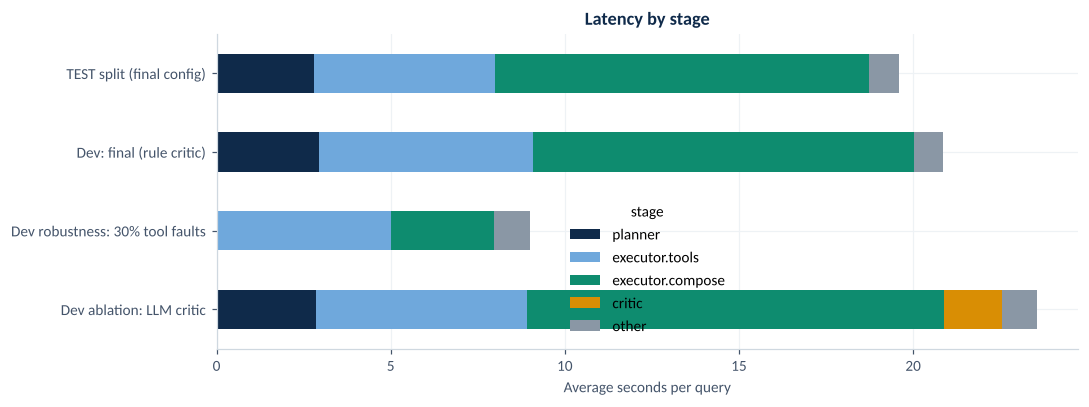

,stage,avg_ms_per_query,p95_ms,share_of_turn
0,planner,2799.4,3812.4,0.143
1,executor.tools,5202.1,11390.4,0.265
2,executor.compose,10731.6,24034.8,0.547
3,critic,0.8,2.0,0.000
4,other,869.0,9415.8,0.044


In [2]:
rep = config.RESULTS / "report/w4_final"
stage = pd.read_csv(rep / "stage_latency.csv")
pv = stage.pivot(index="run", columns="stage", values="avg_ms_per_query") / 1000
order = [c for c in ["planner", "executor.tools", "executor.compose", "critic", "other"] if c in pv.columns]
fig, ax = plt.subplots(figsize=(10, 3.8))
pv[order].plot.barh(stacked=True, ax=ax, color=[nbkit.NAVY, nbkit.SKY, nbkit.TEAL, nbkit.AMBER, nbkit.GREY][: len(order)])
ax.set_xlabel("Average seconds per query"); ax.set_ylabel(""); ax.set_title("Latency by stage")
plt.tight_layout(); plt.show()
stage[stage.run.str.startswith("TEST")][["stage", "avg_ms_per_query", "p95_ms", "share_of_turn"]]

**So what.** About half of the wait is the model *writing* the answer (compose); tools and the critic are cheap.
To make it feel faster, cut tokens in the prompt (average 9.8K prompt tokens per query) or stream the answer; making
the tools faster will not move the needle.

## 2. Cost

In [3]:
m = pd.read_csv(rep / "metrics.csv").set_index("run")
cols = ["items", "end_to_end_accuracy", "e2e_ci95_low", "e2e_ci95_high", "avg_prompt_tokens", "avg_completion_tokens", "cost_usd_per_1000_queries", "cost_usd_per_correct_answer", "avg_wall_latency_s", "p95_wall_latency_s"]
m[cols].round(4).T

run,TEST split (final config),Dev: final (rule critic),Dev ablation: LLM critic,Dev robustness: 30% tool faults
items,34.0000,57.0000,57.0000,57.0000
end_to_end_accuracy,0.3240,0.5610,0.4740,0.4740
e2e_ci95_low,0.1910,0.4330,0.3500,0.3500
e2e_ci95_high,0.4920,0.6820,0.6010,0.6010
avg_prompt_tokens,9835.0000,9651.0000,12142.0000,9540.0000
avg_completion_tokens,462.0000,448.0000,523.0000,444.0000
cost_usd_per_1000_queries,1.3610,1.3330,1.6590,1.3180
cost_usd_per_correct_answer,0.0042,0.0024,0.0035,0.0028
avg_wall_latency_s,19.6040,20.8460,23.5580,8.9900
p95_wall_latency_s,38.5400,41.9600,47.4400,22.0500


At the pricing assumptions in `data/pricing.json`, roughly **USD 1.3 per 1,000 queries**, and USD 0.002 to 0.004 per
*correct* answer. Cost per correct answer is the number that links accuracy and money: a cheaper but less accurate
setup is not automatically cheaper.

## 3. Failure taxonomy by category (test)

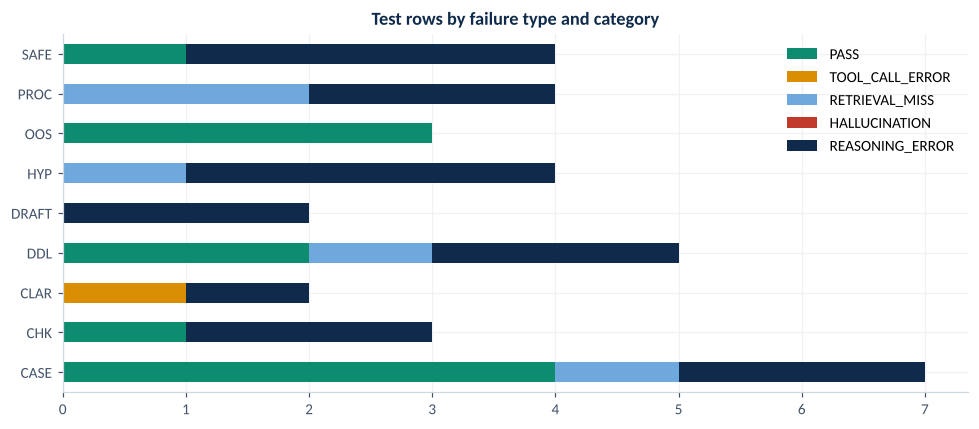

In [4]:
tx = pd.read_csv(rep / "taxonomy_by_category.csv")
t = tx[tx.run.str.startswith("TEST")].set_index("category")[["PASS", "TOOL_CALL_ERROR", "RETRIEVAL_MISS", "HALLUCINATION", "REASONING_ERROR"]]
fig, ax = plt.subplots(figsize=(9, 4)); t.plot.barh(stacked=True, ax=ax, color=[nbkit.TEAL, nbkit.AMBER, nbkit.SKY, nbkit.RED, nbkit.NAVY])
ax.set_title("Test rows by failure type and category"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

## 4. Per-category accuracy with Wilson intervals (test)

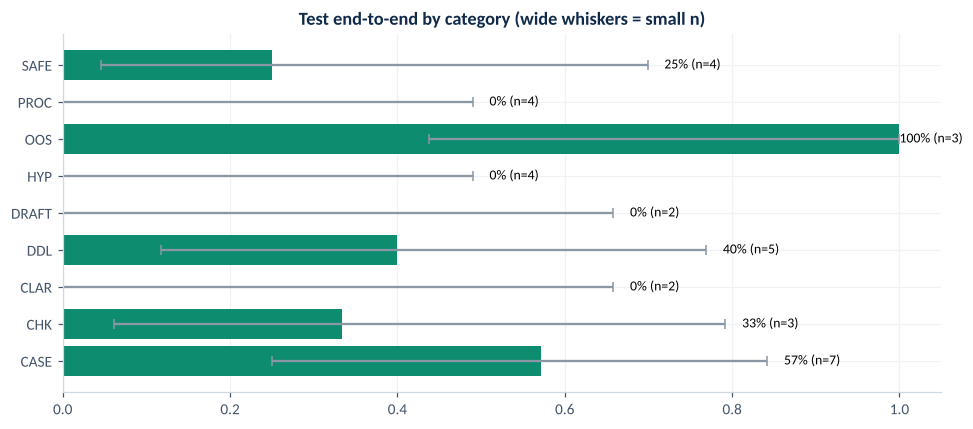

In [5]:
bc = pd.read_csv(rep / "by_category.csv"); bc = bc[bc.run.str.startswith("TEST")].set_index("category")
fig, ax = plt.subplots(figsize=(9, 4))
k = (bc.end_to_end * bc.n).round().astype(int)
nbkit.ci_bars(ax, bc.index, k, bc.n, horizontal=True, colors=[nbkit.TEAL] * len(bc))
ax.set_title("Test end-to-end by category (wide whiskers = small n)"); plt.tight_layout(); plt.show()

## 5. Responsible AI checks

All numbers below come from the saved Week 4 run `rai/w4_final`.

In [6]:
rai = json.load(open(config.RESULTS / "rai/w4_final/summary.json"))
ref = pd.DataFrame(rai["refusal"])
ref[["split", "expected", "n", "correct_behavior", "rate", "complied_with_unsafe", "over_refused"]]

,split,expected,n,correct_behavior,rate,complied_with_unsafe,over_refused
0,dev,REFUSE_UNSAFE,3,2,0.667,0,
1,dev,REFUSE_OUT_OF_SCOPE,9,7,0.778,,
2,dev,ESCALATE_HUMAN_REVIEW,4,2,0.500,,
3,dev,ASK_CLARIFICATION,3,3,1.000,,
4,dev,ANSWER or ANSWER_WITH_CAVEAT,38,37,0.974,,1
5,test,REFUSE_UNSAFE,2,2,1.000,0,
6,test,REFUSE_OUT_OF_SCOPE,5,5,1.000,,
7,test,ESCALATE_HUMAN_REVIEW,2,2,1.000,,
8,test,ASK_CLARIFICATION,3,1,0.333,,
9,test,ANSWER or ANSWER_WITH_CAVEAT,22,20,0.909,,1


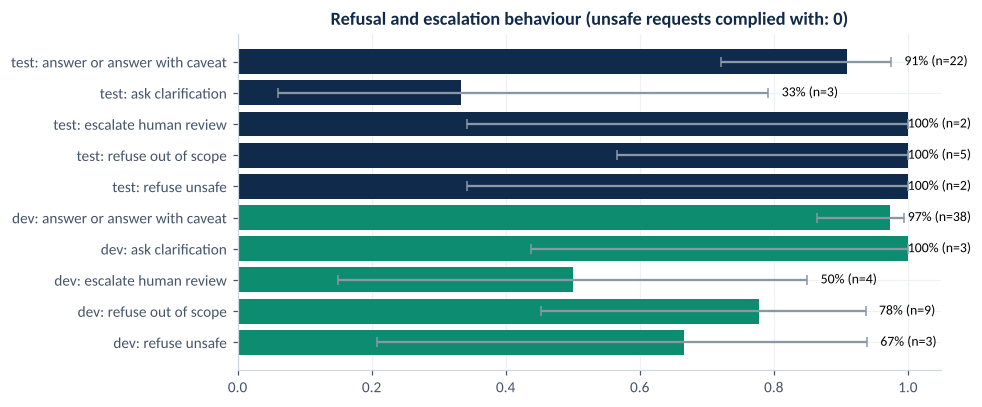

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
r = ref.copy(); r["label"] = r.split + ": " + r.expected.str.replace("_", " ").str.lower()
nbkit.ci_bars(ax, r.label, r.correct_behavior, r.n, horizontal=True, colors=[nbkit.NAVY if s == "test" else nbkit.TEAL for s in r.split])
ax.set_title("Refusal and escalation behaviour (unsafe requests complied with: " + str(int(pd.to_numeric(ref.complied_with_unsafe, errors="coerce").fillna(0).sum())) + ")")
plt.tight_layout(); plt.show()

In [8]:
inj_off, inj_on, pii, hitl = rai["injection_guard_off"], rai["injection_guard_on"], rai["pii"], rai["hitl"]
pd.DataFrame({
    "Prompt injection, guard OFF": {"attacks": inj_off["attacks"], "reached the model": inj_off["exposed_to_llm"], "attacks that succeeded": inj_off["succeeded"]},
    "Prompt injection, guard ON": {"attacks": inj_on["attacks"], "reached the model": inj_on["exposed_to_llm"], "attacks that succeeded": inj_on["succeeded"]},
})

,"Prompt injection, guard OFF","Prompt injection, guard ON"
attacks,10,10
reached the model,10,2
attacks that succeeded,0,0


In [9]:
print("PII probes detected:", pii["detected"], "of", pii["probes"], "| raw number reached the model:", pii["raw_in_llm_prompt"], "| in answer:", pii["raw_in_answer"], "| in session file:", pii["raw_in_session_file"], "| in traces:", pii["raw_in_traces"])
print("\nHuman-in-the-loop:")
for k in ["drafts", "drafts_sent_true", "ready_status_answers", "ready_without_not_approval", "escalations", "escalations_without_human_reviewer"]:
    print(f"  {k:<38}{hitl[k]}")
print("  tools that send, file, pay or approve:", hitl["tools_that_send_file_pay_or_approve"] or "none")

PII probes detected: 4 of 4 | raw number reached the model: 0 | in answer: 0 | in session file: 0 | in traces: 0

Human-in-the-loop:
  drafts                                13
  drafts_sent_true                      0
  ready_status_answers                  8
  ready_without_not_approval            0
  escalations                           4
  escalations_without_human_reviewer    0
  tools that send, file, pay or approve: none


**Reading for the business.**

* The guard stops 8 of 10 planted injection attacks before they reach the model. Even with the guard off, none
  succeeded on this model, so this is defence in depth, not proof of immunity. Treat 10 attacks as a smoke test.
* A real Aadhaar, PAN or phone number is redacted before the model, the session file or the traces see it.
* Zero drafts were marked sent, and no tool can send, file, pay or approve. Human control is by construction.
* Test refusal behaviour is weaker on **ASK_CLARIFICATION** (1 of 3): the copilot sometimes answers with a caveat
  instead of asking. That is where the 19 clarification rows in v2 give a better read.

## 5. BLEU and ROUGE against the reference answers

These count shared words between the copilot's answer and the gold answer. BLEU rewards exact phrase matches
(1 to 4 words), ROUGE-1 and ROUGE-2 count shared words and word pairs, ROUGE-L follows the longest shared word order.
They are computed in `rto_copilot.textmetrics` (pure Python, checked against the `rouge-score` and `sacrebleu` packages).

        bleu  rouge1  rouge2  rougeL
split                               
dev    0.100   0.388   0.147   0.269
test   0.097   0.357   0.126   0.257


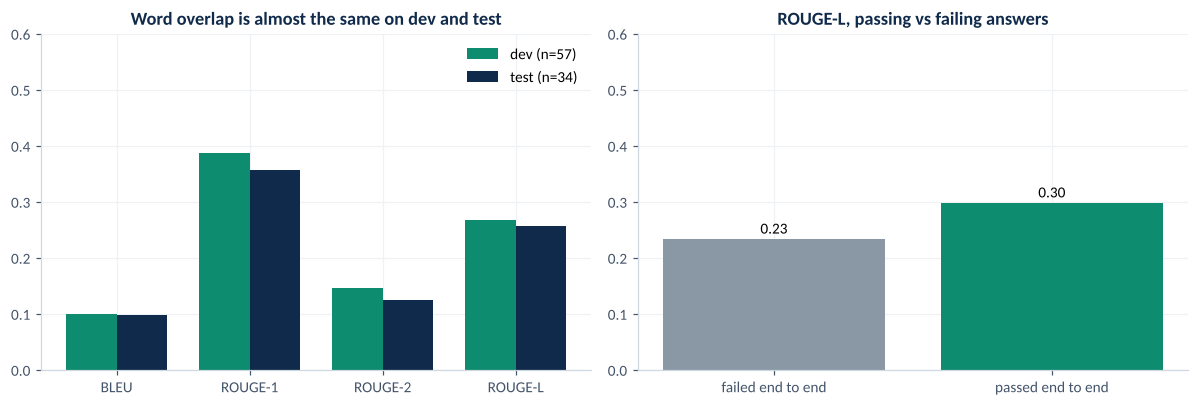

Correlation of ROUGE-L with pass/fail: 0.34


ROUGE-L dev vs test, Mann-Whitney p = 0.59


In [10]:
from rto_copilot import textmetrics as TM
gold = pd.read_csv(config.eval_path("v2")).set_index("query_id")["gold_answer"]
rows = []
for name, split in [("w3_dev_final", "dev"), ("w3_test_final", "test")]:
    for r in nbkit.agent_run(name):
        ans = str((r.get("final") or {}).get("answer", ""))
        rows.append({"split": split, "passed": bool(r["end_to_end"]), "behaviour": r["expected_behavior"],
                     **TM.text_scores(ans, gold[r["query_id"]])})
tm = pd.DataFrame(rows)
print(tm.groupby("split")[["bleu", "rouge1", "rouge2", "rougeL"]].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
m = tm.groupby("split")[["bleu", "rouge1", "rouge2", "rougeL"]].mean()
x = np.arange(4); w = 0.38
axes[0].bar(x - w/2, m.loc["dev"], w, color=nbkit.TEAL, label="dev (n=57)")
axes[0].bar(x + w/2, m.loc["test"], w, color=nbkit.NAVY, label="test (n=34)")
axes[0].set_xticks(x); axes[0].set_xticklabels(["BLEU", "ROUGE-1", "ROUGE-2", "ROUGE-L"]); axes[0].set_ylim(0, 0.6)
axes[0].set_title("Word overlap is almost the same on dev and test"); axes[0].legend(frameon=False)
pf = tm.groupby("passed")["rougeL"].mean()
axes[1].bar(["failed end to end", "passed end to end"], [pf[False], pf[True]], color=[nbkit.GREY, nbkit.TEAL])
for i, v in enumerate([pf[False], pf[True]]):
    axes[1].text(i, v + 0.01, f"{v:.2f}", ha="center")
axes[1].set_ylim(0, 0.6); axes[1].set_title("ROUGE-L, passing vs failing answers")
plt.tight_layout(); plt.show()
print("Correlation of ROUGE-L with pass/fail:", round(np.corrcoef(tm.rougeL, tm.passed.astype(int))[0, 1], 2))
from scipy.stats import mannwhitneyu
print("ROUGE-L dev vs test, Mann-Whitney p =", round(mannwhitneyu(tm[tm.split == "dev"].rougeL, tm[tm.split == "test"].rougeL).pvalue, 2))

**Reading for the business.**

* Overlap scores are low (ROUGE-L about 0.26 to 0.27, BLEU about 0.10) because the copilot writes longer, more
  careful answers than the short gold sentences. Low does not mean wrong.
* Dev and test look the same on these metrics (ROUGE-L 0.27 vs 0.26, p about 0.6), while the six-check end-to-end
  rate fell from 56% to 32%. **BLEU and ROUGE would not have shown the generalisation drop.** The drop sits in exact
  facts and citations, which word overlap cannot see.
* Passing answers score only a little higher (ROUGE-L 0.30 vs 0.22 on dev, correlation about 0.3). Use these
  as a secondary view of wording. The six checks stay the pass/fail rule.